# BreastMNIST: the copied images

Pawłowska et al. (2023, *Data in Brief* 48, 109247) checked BUSI, the source
of BreastMNIST's images. Many images are copies of others: the same scan,
shifted, scaled or cropped. Some copies carry a different label. Their list
holds 153 groups of 346 images, named by BUSI file name.

BreastMNIST does not keep those names. So the loader finds the copies in
BreastMNIST's own images, by the letter's method, geometric registration
([`copies.py`](../copies.py)). It runs once, on first use, and caches the
groups as `copies.csv` beside the downloaded images. Each image's group is
the `copy_group` column of `data.samples`.

Copies matter because a random split can put one copy in the training part
and its twin in the test part. The model is then tested on an image it has
seen. `load_xy(drop_copies=True)` removes them.

This notebook shows what was found, how the copies differ, why simpler tests
miss them, and examples.

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parents[2]))  # repo root, so featsel_datasets imports

from featsel_datasets.medmnist_breastmnist.breastmnist import BreastMNIST
from featsel_datasets.medmnist_breastmnist.copies import copy_pairs, copy_transform

data = BreastMNIST()
samples = data.samples
groups = samples['copy_group'].dropna()

## The groups

A group joins images that are copies of each other, directly or through a
shared image.

In [2]:
labels = samples.loc[groups.index, 'label'].groupby(groups)
conflicting = labels.nunique() > 1
pd.DataFrame({
    "The letter's list": [153, 346, 346 - 153, 6],
    'This search': [groups.nunique(), len(groups), len(groups) - groups.nunique(),
                    conflicting.sum()],
}, index=['Groups', 'Images in them', 'Images beyond the first of each group',
          'Groups mixing malignant with benign or normal'])

,The letter's list,This search
Groups,153,150
Images in them,346,339
Images beyond the first of each group,193,189
Groups mixing malignant with benign or normal,6,6


In [3]:
groups.value_counts().value_counts().sort_index().rename_axis('images in the group').rename('groups')

images in the group
2    122
3     21
4      5
5      1
7      1
Name: groups, dtype: Int64

The two agree closely. A few copies may be mirrored, which SIFT keypoints do
not match.

## How the copies differ

The search is run again here, to get each confirmed pair with the affine
transform that maps one image onto the other. It takes about 40 seconds.

In [4]:
pairs = copy_pairs(data.images, data.embeddings.to_numpy())
images = data.images.reshape(len(data.images), -1).astype(float)
first, second = images[pairs['first']], images[pairs['second']]
pairs['identical'] = (first == second).all(axis=1)
pairs['aligned'] = (pairs['shift'] < 1) & ((pairs['scale'] - 1).abs() < 0.01)
pairs['grey_diff'] = np.abs(first - second).mean(axis=1)

pd.Series({
    'Pairs of copies': len(pairs),
    'Identical, pixel for pixel': pairs['identical'].sum(),
    'Moved < 1 pixel and scaled < 1%, pixels differ':
        (pairs['aligned'] & ~pairs['identical']).sum(),
    'Shifted or scaled more': (~pairs['aligned']).sum(),
    'Median shift (pixels)': round(pairs['shift'].median(), 1),
    'Largest shift (pixels)': round(pairs['shift'].max()),
    'Scale, smallest': round(pairs['scale'].min(), 2),
    'Scale, largest': round(pairs['scale'].max(), 2),
    'Median grey-level difference unaligned, of 255': round(pairs['grey_diff'].median()),
}, name='value', dtype=object).to_frame()

,value
Pairs of copies,230
"Identical, pixel for pixel",1
"Moved < 1 pixel and scaled < 1%, pixels differ",27
Shifted or scaled more,202
Median shift (pixels),2.0
Largest shift (pixels),28
"Scale, smallest",0.86
"Scale, largest",1.09
"Median grey-level difference unaligned, of 255",11


Only one pair is identical. The rest are the same scan, cropped and resized
separately, so the pixels differ. Aligned by the transform found, they
match closely (the examples below).

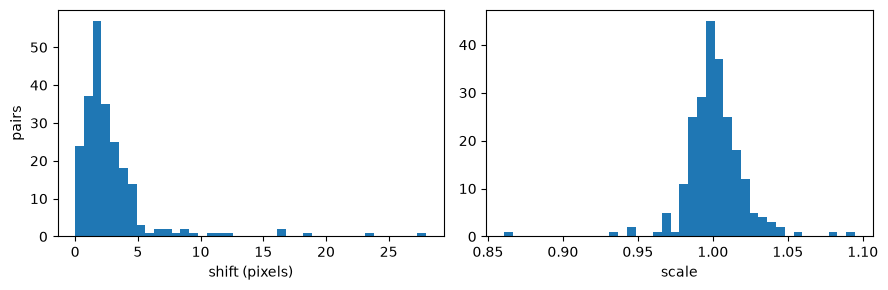

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(pairs['shift'], bins=40)
axes[0].set_xlabel('shift (pixels)')
axes[0].set_ylabel('pairs')
axes[1].hist(pairs['scale'], bins=40)
axes[1].set_xlabel('scale')
fig.tight_layout()

## Why a simpler test would not do

A search for identical images finds one pair. The next simplest test
correlates the pixels of two images as they are, without aligning them.
Below, every pair of the 780 images: the confirmed copies against all other
pairs.

In [6]:
r = np.corrcoef(images)
copy_r = r[pairs['first'], pairs['second']]
group = np.full(len(images), -1)
group[samples.index.get_indexer(groups.index)] = groups
i, j = np.triu_indices_from(r, k=1)
other = (group[i] != group[j]) | (group[i] < 0)
other_r = r[i, j][other]

rows = {}
for threshold in (0.8, 0.85, 0.9, 0.95, other_r.max()):
    rows[f'{threshold:.3f}'] = {'copy pairs above it': (copy_r > threshold).sum(),
                                'other pairs above it': (other_r > threshold).sum()}
print(f'{len(pairs)} copy pairs, {other.sum():,} other pairs; '
      f'the highest correlation of an other pair is {other_r.max():.3f}')
pd.DataFrame(rows).T.rename_axis('correlation threshold')

230 copy pairs, 303,564 other pairs; the highest correlation of an other pair is 0.955


,copy pairs above it,other pairs above it
correlation threshold,,
0.800,216,2405
0.850,204,152
0.900,175,17
0.950,104,3
0.955,89,0


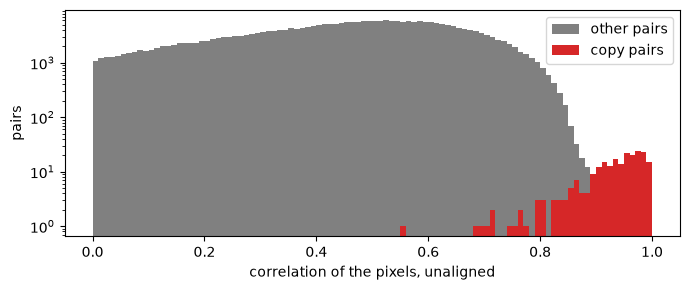

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(0, 1, 101)
ax.hist(other_r, bins=bins, color='grey', label='other pairs')
ax.hist(copy_r, bins=bins, color='tab:red', label='copy pairs')
ax.set_yscale('log')
ax.set_xlabel('correlation of the pixels, unaligned')
ax.set_ylabel('pairs')
ax.legend()
fig.tight_layout()

No threshold separates the two. One low enough to catch most copies also
flags pairs the search did not call copies; one high enough to flag none of
them misses most copies. Aligning the images first is what separates them.

## Examples

Each row shows a pair: the first image, the second, the first warped onto
the second by the transform found, and the absolute difference after
warping, over the part where the two overlap. Dark means equal.

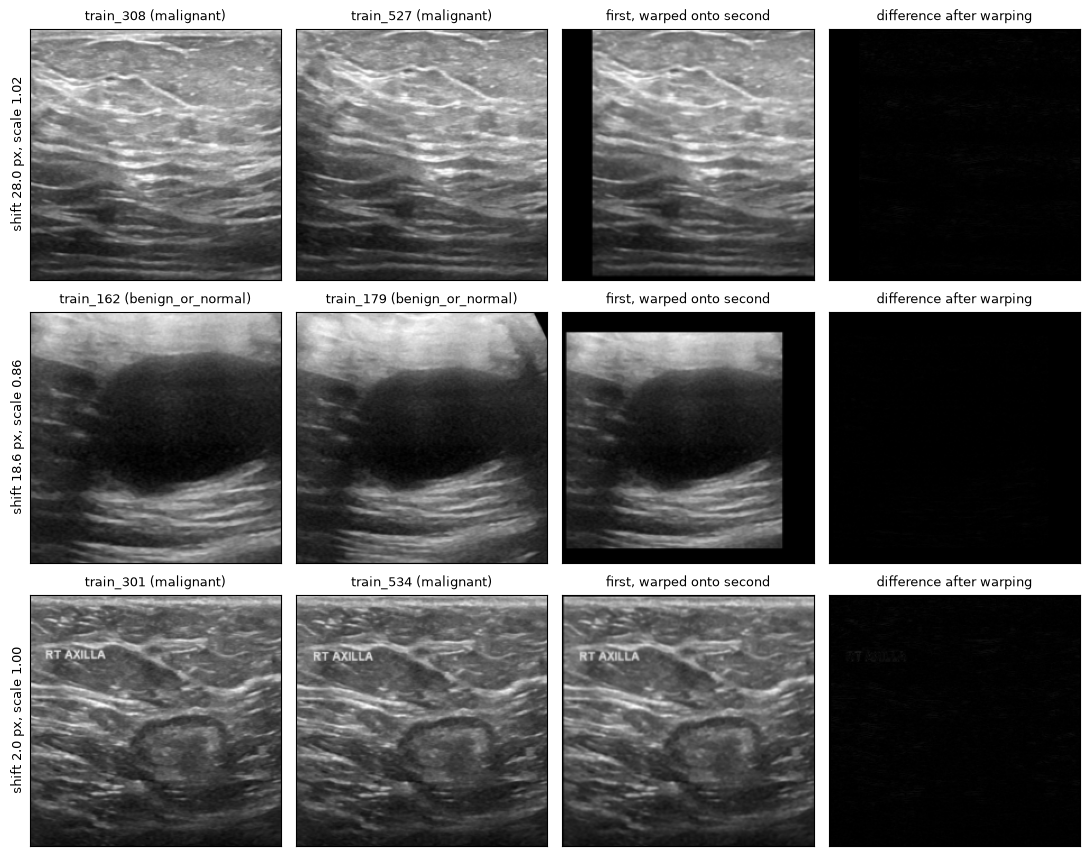

In [8]:
sift = cv2.SIFT.create()
matcher = cv2.BFMatcher(cv2.NORM_L2)


def show(rows, titles):
    fig, axes = plt.subplots(len(rows), 4, figsize=(11, 2.9 * len(rows)))
    for ax_row, (a, b), title in zip(np.atleast_2d(axes), rows, titles):
        ia, ib = data.images[a], data.images[b]
        affine = copy_transform(cv2, matcher, ia, ib, sift.detectAndCompute(ia, None),
                                sift.detectAndCompute(ib, None))
        warped = cv2.warpAffine(ia, affine, ib.shape[::-1])
        overlap = cv2.warpAffine(np.full_like(ia, 255), affine, ib.shape[::-1]) == 255
        diff = np.where(overlap, np.abs(warped.astype(int) - ib.astype(int)), 0)
        names = samples.index
        panels = [(ia, f'{names[a]} ({samples.label.iloc[a]})'),
                  (ib, f'{names[b]} ({samples.label.iloc[b]})'),
                  (warped, 'first, warped onto second'),
                  (diff, 'difference after warping')]
        for ax, (image, label) in zip(ax_row, panels):
            ax.imshow(image, cmap='gray', vmin=0, vmax=255)
            ax.set_title(label, fontsize=9)
            ax.set_xticks([])
            ax.set_yticks([])
        ax_row[0].set_ylabel(title, fontsize=9)
    fig.tight_layout()


examples = [
    pairs.loc[pairs['shift'].idxmax()],
    pairs.loc[(pairs['scale'] - 1).abs().idxmax()],
    pairs.loc[(pairs['shift'] - pairs['shift'].median()).abs().idxmin()],
]
show([(int(p['first']), int(p['second'])) for p in examples],
     [f"shift {p['shift']:.1f} px, scale {p['scale']:.2f}" for p in examples])

The first row is the pair moved furthest, the second the pair scaled most,
and the third a typical pair, at the median shift.

### Copies with different labels

In these groups one copy is labelled malignant and another benign or
normal. The true label is unknown, so `drop_copies` removes such a group
whole.

9 pairs of copies carry different labels


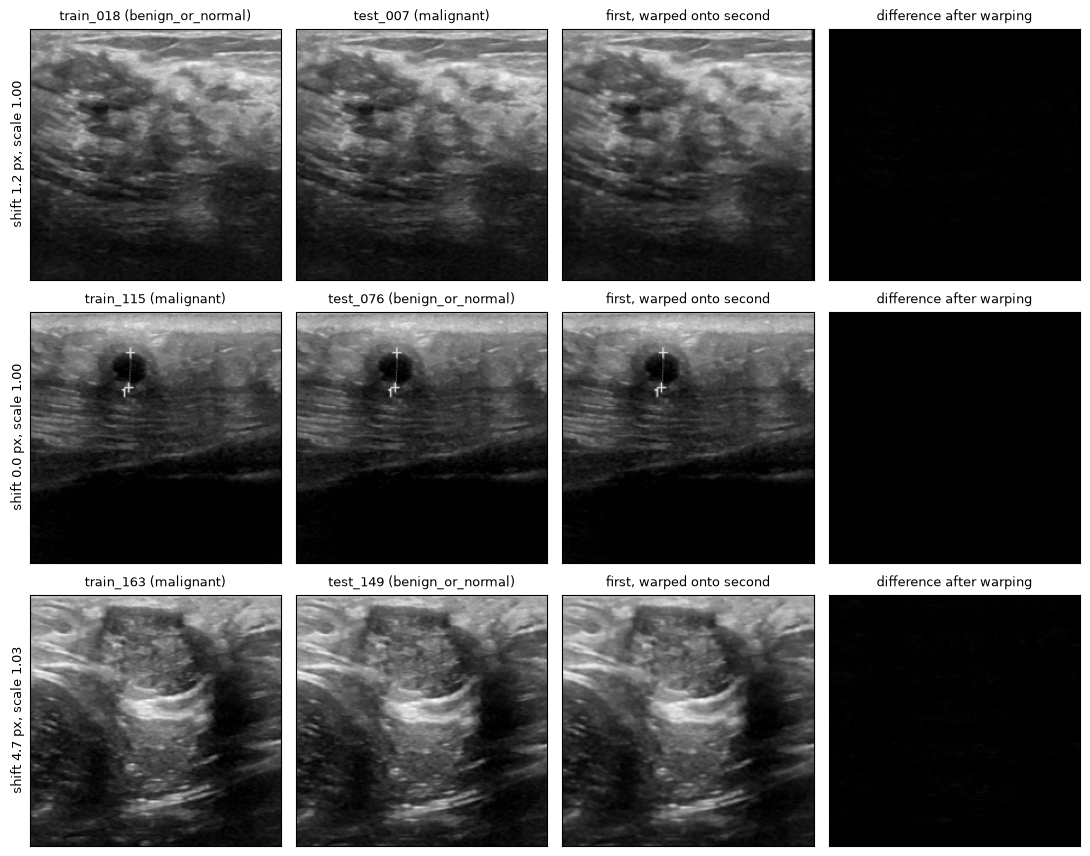

In [9]:
mixed_pairs = pairs[samples['label'].iloc[pairs['first']].to_numpy()
                    != samples['label'].iloc[pairs['second']].to_numpy()]
print(len(mixed_pairs), 'pairs of copies carry different labels')
shown = mixed_pairs.head(3)
show([(int(p['first']), int(p['second'])) for _, p in shown.iterrows()],
     [f"shift {p['shift']:.1f} px, scale {p['scale']:.2f}" for _, p in shown.iterrows()])

## Copies across MedMNIST's own split

MedMNIST ships a fixed train, validation and test split. This project draws
its own splits, but MedMNIST's split has the same problem: copies fall on
both sides of it.

In [10]:
splits = samples.loc[groups.index, 'split'].groupby(groups).nunique()
print(f'{(splits > 1).sum()} of {groups.nunique()} groups span more than one MedMNIST split')
crossing = groups[groups.isin(splits.index[splits > 1])]
samples.loc[crossing.index, 'split'].groupby(crossing).agg(lambda s: ' + '.join(sorted(set(s)))).value_counts()

90 of 150 groups span more than one MedMNIST split


split
test + train          54
train + val           28
test + val             5
test + train + val     3
Name: count, dtype: int64

## This project's view without copies

`load_xy(drop_copies=True)` keeps the first image of each group whose
labels agree, and drops each group whose labels conflict.

In [11]:
from featsel_datasets.medmnist_breastmnist.featsel_view import load_xy

X, y = load_xy(data, drop_copies=True)
print(X.shape)
y.value_counts()

(585, 2048)


label
benign_or_normal    405
malignant           180
Name: count, dtype: int64